In [85]:
pip install requests pandas numpy matplotlib

In [86]:

import requests
import pandas as pd
from getpass import getpass

API_KEY = getpass("Enter your Currents API key: ")

url = "https://api.currentsapi.services/v1/latest-news"

headers = {
    "Authorization": f"Bearer {API_KEY}"
}

params = {
    "language": "en",
    "page_size": 20
}

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

print("Status Code:", response.status_code)

if response.ok:
    result = response.json()

    print("API Connection Successful!")
    print("Response Keys:", result.keys())

    articles = result.get("news", [])

    print("Total Articles:", len(articles))

    df = pd.json_normalize(articles)

    display(df.head())

    print("Dataset Shape:", df.shape)
    print("Columns:", df.columns.tolist())

else:
    print("API Error:", response.text)


Enter your Currents API key: ··········
Status Code: 200
API Connection Successful!
Response Keys: dict_keys(['status', 'news', 'page'])
Total Articles: 20


,id,title,description,url,author,image,language,category,source_category,published
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13 +0000
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00 +0000
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32 +0000
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27 +0000
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35 +0000


Dataset Shape: (20, 10)
Columns: ['id', 'title', 'description', 'url', 'author', 'image', 'language', 'category', 'source_category', 'published']


In [87]:
from google.colab import drive
drive.mount('/content/drive')
import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Global-News-Event-Intelligence"

os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

print("Project folder:", os.getcwd())
print("Google Drive storage is ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/Colab Notebooks/Global-News-Event-Intelligence
Google Drive storage is ready!


In [88]:



print("Dataset Shape:", df.shape)


print("\nAll Columns:")
for col in df.columns:
    print(col)


print("\nDataset Information:")
df.info()


print("\nMissing Values:")
print(df.isnull().sum())


print("\nDuplicate IDs:", df["id"].duplicated().sum())
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Duplicate Titles:", df["title"].duplicated().sum())


print("\nData Types:")
print(df.dtypes)

# Display First 10 Records
pd.set_option("display.max_columns", None)
display(df.head(10))



Dataset Shape: (20, 10)

All Columns:
id
title
description
url
author
image
language
category
source_category
published

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id               20 non-null     object
 1   title            20 non-null     object
 2   description      20 non-null     object
 3   url              20 non-null     object
 4   author           20 non-null     object
 5   image            17 non-null     object
 6   language         20 non-null     object
 7   category         20 non-null     object
 8   source_category  20 non-null     object
 9   published        20 non-null     object
dtypes: object(10)
memory usage: 1.7+ KB

Missing Values:
id                 0
title              0
description        0
url                0
author             0
image              3
language           0
category  

,id,title,description,url,author,image,language,category,source_category,published
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13 +0000
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00 +0000
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32 +0000
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27 +0000
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35 +0000
5,cb3d4a79-39b8-5a58-9f19-202620c0c956,[Computer Chess] How many Elo is a megabyte wo...,Every engine author has a feeling for what a b...,https://dev.to/tinyairun/computer-chess-how-ma...,Tinyai Run,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:22:58 +0000
6,e370c52a-7c08-595b-8cb6-4f3468622d43,Requirement To Disclose Data Centre Operations...,"Johari Abdul Ghani, data centre, law, economy",https://www.bernama.com/en/news.php/?id=2633321,,https://www.bernama.com/storage/photos/2527bcf...,en,[regional],[regional],2026-11-12 08:22:55 +0000
7,01d7c0ea-c23a-5779-9553-59308580fbe3,"PROTUNe 2026 Records Revenue Of RM3.12 Mln, Ex...","PKNS, PROTUNe, students, entrepreneurs, Mahmud Ab",https://www.bernama.com/en/news.php/?id=2633324,,https://www.bernama.com/storage/photos/dd12d8d...,en,[regional],[regional],2026-11-12 08:22:53 +0000
8,437e83dd-aacc-5c62-9d7e-b5ed727f7612,Padi Mills Need Approval To Operate Beyond 7 Pm,"Dewan Rakyat, Agriculture and Food Security Minis",https://www.bernama.com/en/news.php/?id=2633325,,https://www.bernama.com/storage/photos/8031c12...,en,[regional],[regional],2026-11-12 08:22:51 +0000
9,65b0111a-beb7-5c78-8e46-b235b02dcb53,"Malaysia Ready To Resume Trade, Investment Tal...","investment, MITI, Taiwan, Johari Abdul Ghani, ...",https://www.bernama.com/en/news.php/?id=2633329,,https://www.bernama.com/storage/photos/2527bcf...,en,[regional],[regional],2026-11-12 08:22:48 +0000


In [89]:
# Check list values in every column

for col in df.columns:

    count = df[col].apply(
        lambda x: isinstance(x, list)
    ).sum()

    print(f"{col}: {count} list values")

id: 0 list values
title: 0 list values
description: 0 list values
url: 0 list values
author: 0 list values
image: 0 list values
language: 0 list values
category: 20 list values
source_category: 20 list values
published: 0 list values


In [90]:
# Count empty strings in each column

for col in df.columns:

    empty_count = (
        df[col]
        .apply(lambda x: isinstance(x, str) and x.strip() == "")
        .sum()
    )

    print(f"{col}: {empty_count} empty values")

id: 0 empty values
title: 0 empty values
description: 0 empty values
url: 0 empty values
author: 9 empty values
image: 0 empty values
language: 0 empty values
category: 0 empty values
source_category: 0 empty values
published: 0 empty values


In [91]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(missing)

,Missing_Count,Missing_Percentage
id,0,0.0
title,0,0.0
description,0,0.0
url,0,0.0
author,0,0.0
image,3,15.0
language,0,0.0
category,0,0.0
source_category,0,0.0
published,0,0.0


In [92]:
df["published_parsed"] = pd.to_datetime(
    df["published"],
    utc=True,
    errors="coerce"
)

print(df["published_parsed"].dtype)

print("Invalid dates:",
      df["published_parsed"].isna().sum())

display(df[["published", "published_parsed"]].head())

datetime64[ns, UTC]
Invalid dates: 0


,published,published_parsed
0,2026-11-12 08:25:13 +0000,2026-11-12 08:25:13+00:00
1,2026-11-12 08:25:00 +0000,2026-11-12 08:25:00+00:00
2,2026-11-12 08:24:32 +0000,2026-11-12 08:24:32+00:00
3,2026-11-12 08:24:27 +0000,2026-11-12 08:24:27+00:00
4,2026-11-12 08:23:35 +0000,2026-11-12 08:23:35+00:00


In [93]:
for col in ["language", "category", "source_category"]:

    print("\nColumn:", col)

    print("Unique values:")
    print(df[col].value_counts().head(15))


Column: language
Unique values:
language
en    20
Name: count, dtype: int64

Column: category
Unique values:
category
[programming]             8
[regional]                6
[national]                3
[entertainment, funny]    1
[sports]                  1
[general]                 1
Name: count, dtype: int64

Column: source_category
Unique values:
source_category
[programming]             8
[regional]                6
[national]                3
[entertainment, funny]    1
[sports]                  1
[general]                 1
Name: count, dtype: int64


In [94]:

# Create a separate copy of original data

df_clean = df.copy()

print("Original Shape:", df.shape)
print("Cleaning Dataset Shape:", df_clean.shape)


Original Shape: (20, 11)
Cleaning Dataset Shape: (20, 11)


In [95]:
import pandas as pd

# Convert empty strings to missing values
df_clean["description"] = (
    df_clean["description"]
    .replace(r"^\s*$", pd.NA, regex=True)
)

print("Missing Descriptions:",
      df_clean["description"].isna().sum())

Missing Descriptions: 0


In [96]:
print("Missing Images:", df_clean["image"].isna().sum())

Missing Images: 3


In [97]:
# Remove duplicate article IDs
df_clean = df_clean.drop_duplicates(
    subset=["id"],
    keep="first"
)

# Remove duplicate article URLs
df_clean = df_clean.drop_duplicates(
    subset=["url"],
    keep="first"
)

print("Shape after duplicate removal:", df_clean.shape)

Shape after duplicate removal: (20, 11)


In [98]:
df_clean["published"] = pd.to_datetime(
    df_clean["published"],
    utc=True,
    errors="coerce"
)

print(df_clean["published"].dtype)
print("Invalid Dates:", df_clean["published"].isna().sum())

datetime64[ns, UTC]
Invalid Dates: 0


In [99]:
print("FINAL CLEANED DATASET")

print("\nShape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

display(df_clean.head())

FINAL CLEANED DATASET

Shape: (20, 11)

Missing Values:
id                  0
title               0
description         0
url                 0
author              0
image               3
language            0
category            0
source_category     0
published           0
published_parsed    0
dtype: int64

Data Types:
id                               object
title                            object
description                      object
url                              object
author                           object
image                            object
language                         object
category                         object
source_category                  object
published           datetime64[ns, UTC]
published_parsed    datetime64[ns, UTC]
dtype: object


,id,title,description,url,author,image,language,category,source_category,published,published_parsed
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13+00:00,2026-11-12 08:25:13+00:00
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00+00:00,2026-11-12 08:25:00+00:00
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32+00:00,2026-11-12 08:24:32+00:00
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27+00:00,2026-11-12 08:24:27+00:00
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35+00:00,2026-11-12 08:23:35+00:00


In [100]:
# Remove redundant timestamp column

df_clean = df_clean.drop(
    columns=["published_parsed"]
)

print("Final Dataset Shape:", df_clean.shape)
print(df_clean.dtypes)

Final Dataset Shape: (20, 10)
id                              object
title                           object
description                     object
url                             object
author                          object
image                           object
language                        object
category                        object
source_category                 object
published          datetime64[ns, UTC]
dtype: object


In [101]:
print("CLEANING VALIDATION")

print("Rows:", len(df_clean))

print("Duplicate IDs:",
      df_clean["id"].duplicated().sum())

print("Duplicate URLs:",
      df_clean["url"].duplicated().sum())

print("Invalid Dates:",
      df_clean["published"].isna().sum())

print("Missing Values:")
print(df_clean.isnull().sum())

display(df_clean.head())

CLEANING VALIDATION
Rows: 20
Duplicate IDs: 0
Duplicate URLs: 0
Invalid Dates: 0
Missing Values:
id                 0
title              0
description        0
url                0
author             0
image              3
language           0
category           0
source_category    0
published          0
dtype: int64


,id,title,description,url,author,image,language,category,source_category,published
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13+00:00
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00+00:00
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32+00:00
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27+00:00
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35+00:00


In [102]:
import os

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

In [103]:
import json

# Save original API response
with open("data/raw/news_raw.json", "w", encoding="utf-8") as file:
    json.dump(result, file, ensure_ascii=False, indent=4)

# Save original article data
df.to_csv("data/raw/news_raw.csv", index=False)

# Save cleaned dataset
df_clean.to_csv("data/processed/news_cleaned.csv", index=False)

print("All datasets saved successfully!")

All datasets saved successfully!


TOP NEWS PUBLISHERS


,Publisher,Articles
0,dev.to,8
1,bernama.com,6
2,independent.co.uk,2
3,nltimes.nl,1
4,9gag.com,1
5,brisbanetimes.com.au,1
6,news18.com,1


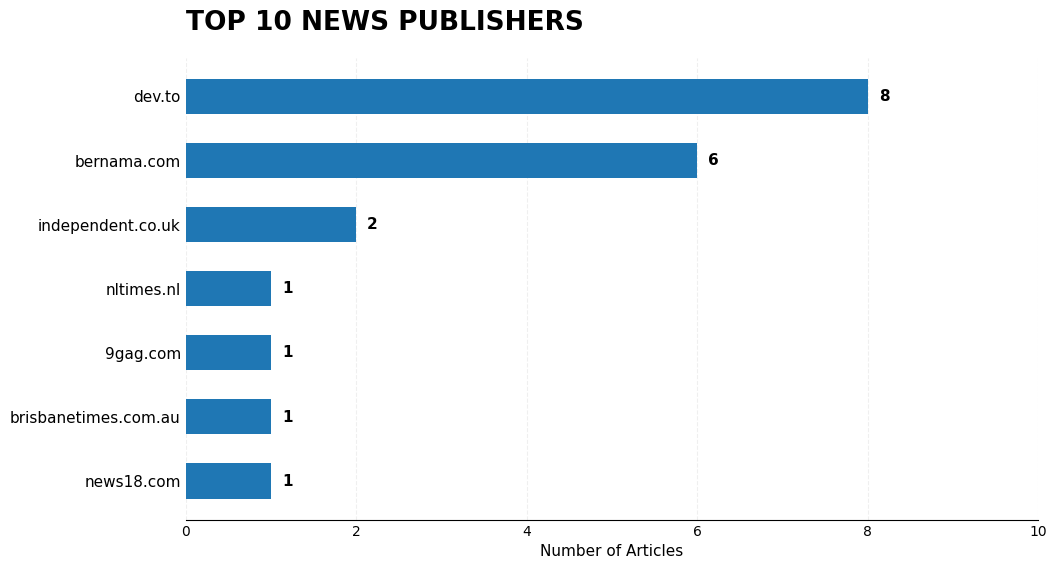

In [104]:

import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlparse

df_clean["publisher"] = df_clean["url"].apply(
    lambda url: urlparse(url).netloc.lower().replace("www.", "")
    if pd.notna(url) else "unknown"
)

# 2. Count articles by publisher
publisher_counts = (
    df_clean["publisher"]
    .value_counts()
    .head(10)
    .sort_values(ascending=False)
)

print("TOP NEWS PUBLISHERS")
display(publisher_counts.rename_axis("Publisher").reset_index(name="Articles"))

# 3. Professional horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    publisher_counts.index[::-1],
    publisher_counts.values[::-1],
    height=0.55
)

# Add values
ax.bar_label(bars, padding=8, fontsize=11, fontweight="bold")

# Titles
ax.set_title(
    "TOP 10 NEWS PUBLISHERS",
    fontsize=19,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Number of Articles", fontsize=11)
ax.set_ylabel("")

# Clean design
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.grid(True, linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.tick_params(axis="y", labelsize=11, length=0)
ax.tick_params(axis="x", length=0)
ax.set_xlim(0, publisher_counts.max() * 1.25)

plt.savefig(
    "visualizations/top_10_news_publishers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
print(df_clean.shape)

(20, 11)


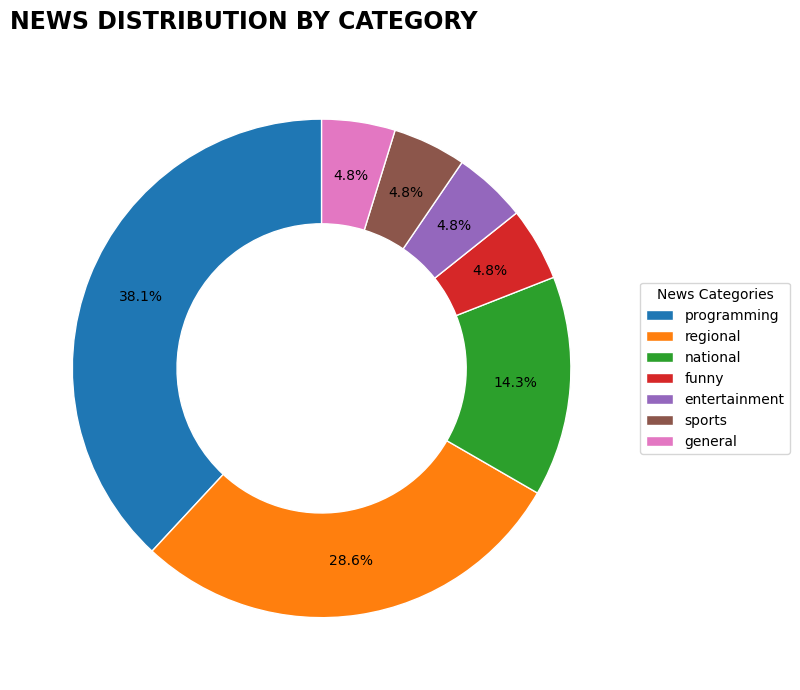

In [106]:
import matplotlib.pyplot as plt

# Count articles by category
category_counts = (
    df_clean["category"]
    .explode()
    .value_counts()
)

# Create donut chart
fig, ax = plt.subplots(figsize=(10, 7))

wedges, texts, autotexts = ax.pie(
    category_counts,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white")
)

# Add category legend
ax.legend(
    wedges,
    category_counts.index,
    title="News Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title(
    "NEWS DISTRIBUTION BY CATEGORY",
    fontsize=17,
    fontweight="bold",
    loc="left",
    pad=20
)

plt.tight_layout()

# Save chart
plt.savefig(
    "visualizations/news_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [107]:
# Convert category lists into individual rows
category_publisher = df_clean.explode("category")

# Create category-publisher summary
publisher_category = pd.crosstab(
    category_publisher["publisher"],
    category_publisher["category"]
)

# Select top 5 publishers
top_publishers = (
    df_clean["publisher"]
    .value_counts()
    .head(5)
    .index
)

chart_data = publisher_category.loc[
    publisher_category.index.intersection(top_publishers)
]

display(chart_data)

category,entertainment,funny,general,national,programming,regional,sports
publisher,,,,,,,
9gag.com,1,1,0,0,0,0,0
bernama.com,0,0,0,0,0,6,0
dev.to,0,0,0,0,8,0,0
independent.co.uk,0,0,0,2,0,0,0
nltimes.nl,0,0,0,1,0,0,0


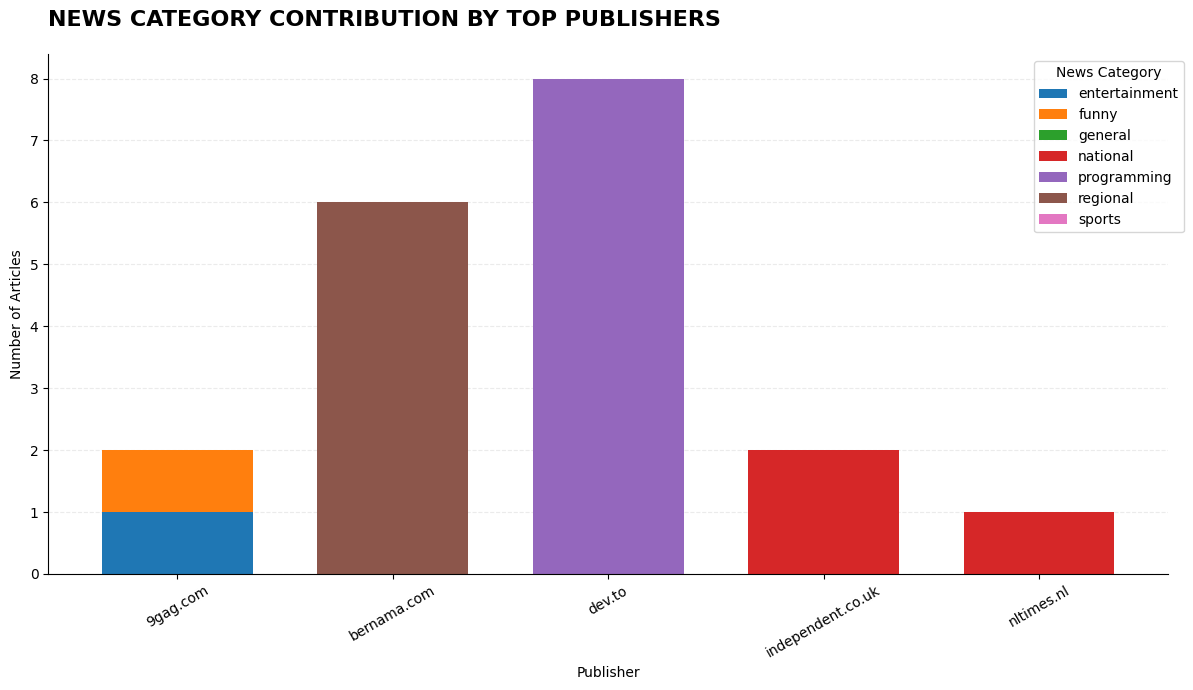

In [108]:
import matplotlib.pyplot as plt

ax = chart_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7),
    width=0.7
)

ax.set_title(
    "NEWS CATEGORY CONTRIBUTION BY TOP PUBLISHERS",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Publisher")
ax.set_ylabel("Number of Articles")
ax.tick_params(axis="x", rotation=30)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.legend(title="News Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

plt.savefig(
    "visualizations/publisher_category_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [109]:
import requests
import pandas as pd


url = "https://api.currentsapi.services/v1/latest-news"

headers = {
    "Authorization": f"Bearer {API_KEY}"
}

params = {
    "language": "en",
    "page_size": 20
}

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

print("Status Code:", response.status_code)

if response.ok:
    result_new = response.json()
    articles_new = result_new.get("news", [])

    df_new = pd.json_normalize(articles_new)

    print("New articles fetched:", len(df_new))
    display(df_new.head())
else:
    print("API Error:", response.text)

Status Code: 200
New articles fetched: 20


,id,title,description,url,author,image,language,category,source_category,published
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13 +0000
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00 +0000
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32 +0000
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27 +0000
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35 +0000


In [110]:
print("EMPTY STRING CHECK")

for column in df_new.columns:
    empty_count = (
        df_new[column]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(column, ":", empty_count)

EMPTY STRING CHECK
id : 0
title : 0
description : 0
url : 0
author : 9
image : 0
language : 0
category : 0
source_category : 0
published : 0


In [111]:
import numpy as np

# Replace empty strings with NaN
df_new["author"] = df_new["author"].replace("", np.nan)

# Check missing values again
print(df_new.isnull().sum())

id                 0
title              0
description        0
url                0
author             9
image              3
language           0
category           0
source_category    0
published          0
dtype: int64


In [112]:
# Convert published column into datetime format
df_new["published"] = pd.to_datetime(
    df_new["published"],
    errors="coerce",
    utc=True
)

# Count invalid dates
print("Invalid Dates:", df_new["published"].isna().sum())

# Display date information
print("\nPublication Date Range:")
print("Earliest:", df_new["published"].min())
print("Latest:", df_new["published"].max())

Invalid Dates: 0

Publication Date Range:
Earliest: 2026-11-12 08:21:23+00:00
Latest: 2026-11-12 08:25:13+00:00


In [113]:
print("Duplicate IDs:", df_new["id"].duplicated().sum())
print("Duplicate URLs:", df_new["url"].duplicated().sum())

Duplicate IDs: 0
Duplicate URLs: 0


In [114]:
# Create cleaned copy
df_new_clean = df_new.copy()

# Remove duplicate IDs and URLs
df_new_clean = df_new_clean.drop_duplicates(
    subset="id"
)

df_new_clean = df_new_clean.drop_duplicates(
    subset="url"
)

# Reset index
df_new_clean = df_new_clean.reset_index(drop=True)

# Final validation
print("Cleaned Dataset Shape:", df_new_clean.shape)
print("Missing Values:")
print(df_new_clean.isnull().sum())

Cleaned Dataset Shape: (20, 10)
Missing Values:
id                 0
title              0
description        0
url                0
author             9
image              3
language           0
category           0
source_category    0
published          0
dtype: int64


In [115]:
# Original API columns
original_columns = [
    "id", "title", "description", "url", "author",
    "image", "language", "category",
    "source_category", "published"
]

# Combine only the original API columns
df_final = pd.concat(
    [
        df_clean[original_columns],
        df_new_clean[original_columns]
    ],
    ignore_index=True
)

# Remove cross-batch duplicates
df_final = df_final.drop_duplicates(subset="id")
df_final = df_final.drop_duplicates(subset="url")

df_final = df_final.reset_index(drop=True)

print("FINAL CLEANED DATASET")
print("Rows:", df_final.shape[0])
print("Columns:", df_final.shape[1])

display(df_final.head())

FINAL CLEANED DATASET
Rows: 20
Columns: 10


,id,title,description,url,author,image,language,category,source_category,published
0,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,None,en,"[entertainment, funny]","[entertainment, funny]",2026-11-12 08:25:13+00:00
1,922d56b1-f0e4-5fc1-985d-93a76518fe3c,Appeal starts against Rotterdam medical studen...,The appeal trial against Fouad L. is starting ...,https://nltimes.nl/2026/11/12/appeal-starts-ro...,,https://nltimes.nl/sites/nltimes.nl/files/styl...,en,[national],[national],2026-11-12 08:25:00+00:00
2,6cc3baf0-1cdc-51b9-8958-f1519836f619,ACH Return Codes Explained: R01–R85 and How to...,ACH Return Codes Explained: R01–R85 and How to...,https://dev.to/payout_rail/ach-return-codes-ex...,Payout Rail,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:32+00:00
3,348a516b-d833-52c6-876d-abf7a90e2c24,Playwright Email Tests Need a Quarantine Queue,Playwright Email Tests Need a Quarantine Queue...,https://dev.to/silviutech/playwright-email-tes...,Silviu Technology,https://media2.dev.to/dynamic/image/width=1200...,en,[programming],[programming],2026-11-12 08:24:27+00:00
4,17f07452-df45-564b-8447-98772db716ea,Strictly’s Shirley Ballas addresses show futur...,Strictly Come Dancing star Shirley Ballas addr...,https://www.independent.co.uk/tv/culture/bbc-s...,Holly Patrick,https://cdn.ex.co/video-uploads/production/001...,en,[national],[national],2026-11-12 08:23:35+00:00


In [116]:
import os

# Create a folder for project data
os.makedirs("data/processed", exist_ok=True)

# Save final cleaned dataset
df_final.to_csv(
    "data/processed/news_final_cleaned.csv",
    index=False
)

print("Final dataset saved successfully!")
print("File: data/processed/news_final_cleaned.csv")

Final dataset saved successfully!
File: data/processed/news_final_cleaned.csv


In [117]:
# Dataset overview
print("DATASET OVERVIEW")

print("\nShape:")
print(df_final.shape)

print("\nColumn Names:")
print(df_final.columns.tolist())

print("\nData Types:")
print(df_final.dtypes)

print("\nStatistical Summary:")
display(df_final.describe(include="all"))


DATASET OVERVIEW

Shape:
(20, 10)

Column Names:
['id', 'title', 'description', 'url', 'author', 'image', 'language', 'category', 'source_category', 'published']

Data Types:
id                              object
title                           object
description                     object
url                             object
author                          object
image                           object
language                        object
category                        object
source_category                 object
published          datetime64[ns, UTC]
dtype: object

Statistical Summary:


,id,title,description,url,author,image,language,category,source_category,published
count,20,20,20,20,20,17,20,20,20,20
unique,20,20,20,20,12,16,1,6,6,NaN
top,e805268e-7057-5d08-9315-9c5e641373b6,Found this pattern in the bedroom of my new ap...,"Tags: and ill see you tomorrow1 points, 14 com...",http://9gag.com/gag/a0o85Kn,,https://www.bernama.com/storage/photos/2527bcf...,en,[programming],[programming],NaN
freq,1,1,1,1,9,2,20,8,8,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:22:58.249999872+00:00
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:21:23+00:00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:22:22+00:00
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:22:46.500000+00:00
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:23:07.249999872+00:00
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-12 08:25:13+00:00


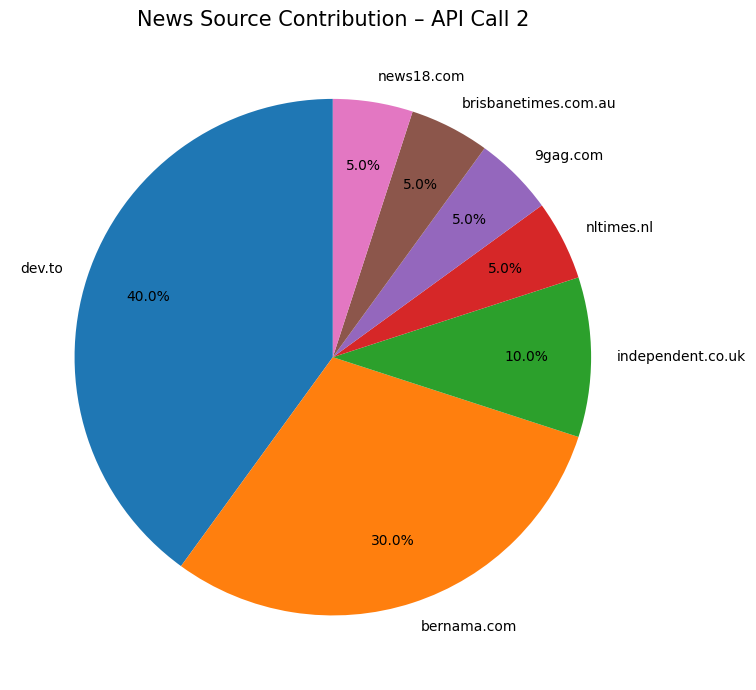

In [118]:
import matplotlib.pyplot as plt
from urllib.parse import urlparse

# Extract news website domains
df_new_clean["publisher"] = df_new_clean["url"].apply(
    lambda url: urlparse(url).netloc.lower().replace("www.", "")
)

# Count articles from each news source
source_counts = df_new_clean["publisher"].value_counts()

# Create pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    source_counts,
    labels=source_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)

plt.title("News Source Contribution – API Call 2", fontsize=15)
plt.tight_layout()

plt.savefig(
    "visualizations/news_source_contribution_api2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [119]:
# Overall dataset information

print("FINAL NEWS DATASET OVERVIEW")
print("-" * 40)

print("Total Articles:", df_final.shape[0])
print("Total Columns:", df_final.shape[1])

print("\nMissing Values:")
print(df_final.isnull().sum())

print("\nDuplicate Article IDs:", df_final["id"].duplicated().sum())
print("Duplicate URLs:", df_final["url"].duplicated().sum())

print("\nPublication Date Range:")
print("First Article:", df_final["published"].min())
print("Last Article:", df_final["published"].max())

print("\nLanguage Distribution:")
print(df_final["language"].value_counts())

FINAL NEWS DATASET OVERVIEW
----------------------------------------
Total Articles: 20
Total Columns: 10

Missing Values:
id                 0
title              0
description        0
url                0
author             0
image              3
language           0
category           0
source_category    0
published          0
dtype: int64

Duplicate Article IDs: 0
Duplicate URLs: 0

Publication Date Range:
First Article: 2026-11-12 08:21:23+00:00
Last Article: 2026-11-12 08:25:13+00:00

Language Distribution:
language
en    20
Name: count, dtype: int64


In [120]:
# News Category Analysis

category_counts = df_final["category"].explode().value_counts()

category_summary = (
    category_counts
    .rename_axis("Category")
    .reset_index(name="Article Count")
)

print("NEWS CATEGORY DISTRIBUTION")
display(category_summary)

NEWS CATEGORY DISTRIBUTION


,Category,Article Count
0,programming,8
1,regional,6
2,national,3
3,funny,1
4,entertainment,1
5,sports,1
6,general,1


In [121]:
print(df_clean.shape)
print(df_new_clean.shape)
print(df_final.shape)

(20, 11)
(20, 11)
(20, 10)


In [122]:
original_columns = [
    "id", "title", "description", "url", "author",
    "image", "language", "category",
    "source_category", "published"
]

combined_check = pd.concat(
    [
        df_clean[original_columns],
        df_new_clean[original_columns]
    ],
    ignore_index=True
)

print("Total collected:", len(combined_check))
print("Duplicate IDs:", combined_check["id"].duplicated().sum())
print("Duplicate URLs:", combined_check["url"].duplicated().sum())
print("Final unique articles:", len(df_final))

Total collected: 40
Duplicate IDs: 20
Duplicate URLs: 20
Final unique articles: 20


In [123]:
print(df_clean["category"].explode().value_counts())

category
programming      8
regional         6
national         3
funny            1
entertainment    1
sports           1
general          1
Name: count, dtype: int64
